# TAREA 3: APRENDIZAJE NO SUPERVISADO

In [1]:
import pandas as pd
import numpy as np

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("rendimiento_estudiantes.csv", sep=";")

En primer lugar, realizamos una selección de las variables que resultan más interesantes para la búsqueda de patrones o identificar perfiles (eligiendo variables relacionadas tanto con la dimensión socioeconómica como con la demográfica o la académica)

In [3]:
cols_clustering = [
    "edad_al_matricularse",
    "nota_admision",
    "nota_media_1sem",
    "asignaturas_1sem_aprobadas",
    "asignaturas_1sem_evaluadas",
    "asignaturas_1sem_matriculadas",
    "becado",
    "deudor"
]

X_cluster = df[cols_clustering]

Convertimos las variables categóricas y escalamos los datos

In [4]:
X_cluster = pd.get_dummies(X_cluster, drop_first=True)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_cluster)

Intentamos determinar cuál sería el número de clusters (K) óptimo utilizando el Método del Codo

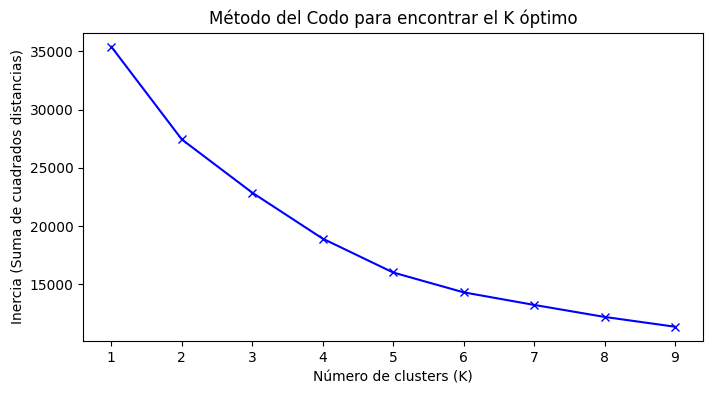

In [5]:
inercias = []
K_range = range(1, 10)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inercias.append(kmeans.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(K_range, inercias, 'bx-')
plt.xlabel('Número de clusters (K)')
plt.ylabel('Inercia (Suma de cuadrados distancias)')
plt.title('Método del Codo para encontrar el K óptimo')
plt.show()

Vemos que la curva se suaviza en torno a k=3 o k=4. Aunque es cierto que no se visualiza claramente esa forma de "codo". Por lo tanto, vamos a probar con otro método: el Método de la Silueta (Silhouette method)

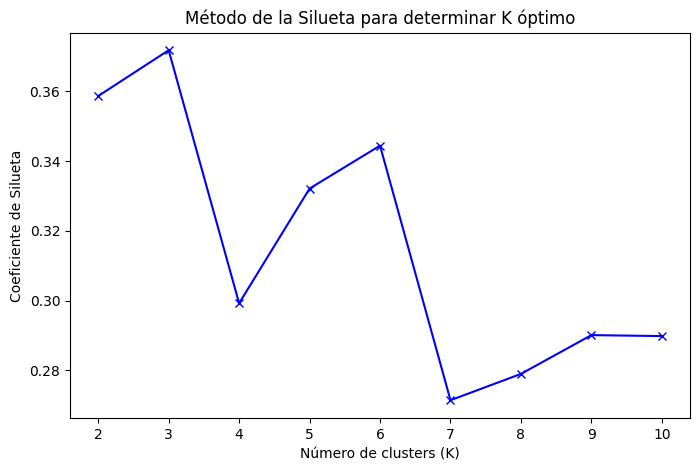

In [6]:
silhouette_scores = []
K_range = range(2, 11) # La silueta requiere al menos 2 clusters

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    cluster_labels = kmeans.fit_predict(X_scaled) 
    
    # Calculamos el score de silueta
    silhouette_avg = silhouette_score(X_scaled, cluster_labels)
    silhouette_scores.append(silhouette_avg)

# Visualización
plt.figure(figsize=(8, 5))
plt.plot(K_range, silhouette_scores, 'bx-')
plt.xlabel('Número de clusters (K)')
plt.ylabel('Coeficiente de Silueta')
plt.title('Método de la Silueta para determinar K óptimo')
plt.show()

El valor de K que tenga el coeficiente de silueta más alto es el que ofrece la mejor separación entre grupos y la mejor cohesión interna. En la gráfica observamos que claramente es k=3

Asimismo, realizamos algunas pruebas con distintos valores de k y hemos podido comprobar que el valor óptimo es k=3. Pues así evitamos crear clusters que no aportan información adicional y que dividen un perfil ya existente en dos grupos con comportamientos casi idénticos.

Para validar la estabilidad real del modelo, comparamos los centroides (medias) de los clusters utilizando dos semillas distintas:

In [7]:
# Definimos dos modelos con semillas diferentes
km42 = KMeans(n_clusters=3, random_state=42, n_init=20).fit(X_scaled)
km110 = KMeans(n_clusters=3, random_state=110, n_init=20).fit(X_scaled)

# Extraemos y ordenamos las medias para comparar los perfiles
medias_42 = sorted(df.groupby(km42.labels_)['nota_media_1sem'].mean())
medias_110 = sorted(df.groupby(km110.labels_)['nota_media_1sem'].mean())

print(f"Perfiles detectados (Semilla 42):  {medias_42}")
print(f"Perfiles detectados (Semilla 110): {medias_110}")

Perfiles detectados (Semilla 42):  [0.02847222222222222, 12.623562330985433, 12.710580734536318]
Perfiles detectados (Semilla 110): [0.02847222222222222, 12.623562330985433, 12.710580734536318]


Vemos como las medias de una de las variables clave (en este caso la nota media del primer semestre) se mantienen constantes independientemente de la semilla. Por lo tanto, confirmamos que los perfiles identificados son estructuras reales en los datos y no fruto del azar

Ahora sí, calculamos las k-means

In [8]:
kmeans = KMeans(n_clusters=3, random_state=42)
clusters = kmeans.fit_predict(X_scaled)

df["cluster"] = clusters

In [9]:
df['cluster'].value_counts()

cluster
0    3112
2    1017
1     295
Name: count, dtype: int64

Aplicamos PCA para visualizar

In [10]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

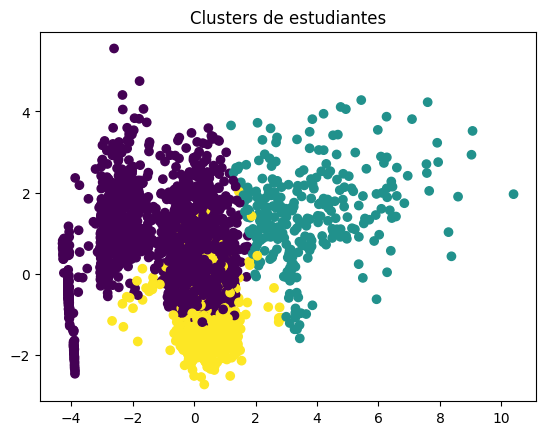

In [11]:
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=clusters)
plt.title("Clusters de estudiantes")
plt.show()

Veamos cuales son los porcentajes de abandono, graduado y matriculado para cada uno de los clusters

In [12]:
pd.crosstab(df["cluster"], df["objetivo"], normalize="index")

objetivo,abandono,graduado,matriculado
cluster,,,
0,0.396851,0.400064,0.203085
1,0.257627,0.610169,0.132203
2,0.108161,0.770895,0.120944


Ahora veamos las medias de las variables númericas en cada cluster para analizar si hay alguna relación entre ellas y los resultados que acabamos de observar. Además, podremos ver cuáles son las variables que mejor separan los clusters

In [13]:
df.groupby("cluster").mean(numeric_only=True).T

cluster,0,1,2
orden_solicitud,1.718509,1.152542,1.923304
nota_cualificacion_previa,132.453535,131.316610,133.478368
nota_admision,126.781395,129.556271,126.832252
edad_al_matricularse,23.528920,29.474576,20.656834
asignaturas_1sem_convalidadas,0.173522,8.301695,0.149459
asignaturas_1sem_matriculadas,5.614396,12.976271,6.333333
asignaturas_1sem_evaluadas,7.592224,16.759322,8.007866
asignaturas_1sem_aprobadas,3.770244,11.332203,5.649951
nota_media_1sem,9.778689,12.623395,12.703846
asignaturas_1sem_sin_evaluacion,0.134640,0.440678,0.058997


Riesgo de abandono por cluster:

In [14]:
df.groupby("cluster")["objetivo"].apply(lambda x: (x=="abandono").mean())

cluster
0    0.396851
1    0.257627
2    0.108161
Name: objetivo, dtype: float64